In [314]:
import pandas as pd
import numpy as np
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score, 
                             f1_score, confusion_matrix, log_loss, 
                             classification_report, average_precision_score, precision_recall_curve)
from catboost import CatBoostClassifier

import optuna

import warnings
warnings.filterwarnings("ignore")

In [315]:
pd.set_option('display.max_columns', None)

# Preprocessing Data

In [316]:
# Import the data since we want to be able to change our experiments individually.
Xt = pd.read_csv("modeling_data/train.csv")
yt = Xt["target"]
Xt.drop(columns=["target"],inplace=True)
Xv = pd.read_csv("modeling_data/validation.csv")
yv = Xv["target"]
Xv.drop(columns=["target"],inplace=True)

Xt.drop(columns=["patient_nbr"],inplace=True)
Xv.drop(columns=["patient_nbr"],inplace=True)

In [317]:
def group_medications(df):
    groups = {
        "biguanide": ["metformin"],
        "meglitinide": ["repaglinide", "nateglinide"],
        "sulfonylurea_gen1": ["chlorpropamide", "acetohexamide", "tolbutamide", "tolazamide"],
        "sulfonylurea_gen2": ["glimepiride", "glipizide", "glyburide"],
        "thiazolidinedione": ["pioglitazone", "rosiglitazone", "troglitazone"],
        "alpha_glucosidase_inhibitor": ["acarbose", "miglitol"],
        "biguanide_sulfonylurea_gen2": ["glyburide-metformin", "glipizide-metformin"],
        "biguanide_thiazolidinedione": ["metformin-rosiglitazone", "metformin-pioglitazone"],
        "sulfonylurea_gen2_thiazolidinedione": ["glimepiride-pioglitazone"],
    }

    result = df.copy()
    priority = ["Up", "Down", "Steady"]

    for group, medications in groups.items():
        columns = df.columns.intersection(medications)
        if len(columns):
            values = df[columns]
            result = result.drop(columns=columns)
            result[group] = np.select([values.eq(status).any(axis=1) for status in priority], priority, default="No")

    return result

In [318]:
# Xt=group_medications(Xt)
# Xv=group_medications(Xv)

In [319]:
# Removing outliers

# Remove entries 4 standard deviations out
def remove_upper_outliers(df, columns, n_std=5):
    x = df[columns]
    upper = x.mean() + n_std * x.std(ddof=0)
    remove = x.gt(upper).any(axis=1)

    print(f"Removed {remove.sum():,} of {len(df):,} rows")
    return df.loc[~remove].copy()

numerical_features = [
    "time_in_hospital",
    "num_lab_procedures",
    "num_procedures",
    "num_medications",
    "number_outpatient",
    "number_emergency",
    "number_inpatient",
    "number_diagnoses",
]

In [320]:
# train_filtered = remove_upper_outliers(Xt, numerical_features)
# Xt = train_filtered.drop(columns="target")
# yt = train_filtered["target"]

In [321]:
def add_numerical_entries(df):

    df['total_visits'] = df['number_outpatient'] + df['number_inpatient'] + df['number_outpatient']

    return df

In [322]:
def group_diagnoses(df):
    import pandas as pd

    ranges = {"Circulatory": (390, 459), "Respiratory": (460, 519),
        "Digestive": (520, 579), "Genitourinary": (580, 629),
        "Musculoskeletal": (710, 739), "Neoplasms": (140, 239), "Injury": (800, 999)}
    
    symptoms = {785: "Circulatory", 786: "Respiratory", 787: "Digestive", 788: "Genitourinary"}

    def categorize(value):
        if pd.isna(value):
            return "Missing"

        code = str(value).strip().upper()
        if code in {"", "?", "NAN", "NONE", "MISSING"}:
            return "Missing"

        # Supplementary V/E codes belong to the broad Other category.
        if code.startswith(("V", "E")):
            return "Other"

        try:
            number = float(code)
            if not 1 <= number < 1000:
                return "Other"
            code = int(number)  # 250.13 -> 250, 459.9 -> 459
        except ValueError:
            return "Other"

        if code == 250:
            return "Diabetes"
        if code in symptoms:
            return symptoms[code]
        for group, (lower, upper) in ranges.items():
            if lower <= code <= upper:
                return group
        return "Other"

    result = df.copy()
    for column in ("diag_1", "diag_2", "diag_3", "diaga_3"):
        if column in result.columns:
            result[column] = result[column].map(categorize)

    return result

In [323]:
# Xt = group_diagnoses(Xt)
# Xv = group_diagnoses(Xv)

In [324]:
# prepare for catboost
num_cols = Xt.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in Xt.columns if c not in num_cols]


# careful! catboost demands categorical columns to have string entry
Xt_cb, Xv_cb = Xt.copy(), Xv.copy()
for c in cat_cols:
    for df in (Xt_cb, Xv_cb):
        df[c] = df[c].astype(object).where(df[c].notna(), "missing").astype(str)

In [325]:
Xt.head(10)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed
0,1,41,0,1,0,0,0,1,Caucasian,Female,[0-10),?,NaN,Not Mapped,Physician Referral,?,Pediatrics-Endocrinology,250.83,?,?,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No
1,3,59,0,18,0,0,0,9,Caucasian,Female,[10-20),?,Emergency,Discharged to home,Emergency Room,?,?,276,250.01,255,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes
2,2,44,1,16,0,0,0,7,Caucasian,Male,[30-40),?,Emergency,Discharged to home,Emergency Room,?,?,8,250.43,403,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes
3,3,31,6,16,0,0,0,9,Caucasian,Male,[50-60),?,Urgent,Discharged to home,Clinic Referral,?,?,414,411,250,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes
4,4,70,1,21,0,0,0,7,Caucasian,Male,[60-70),?,Elective,Discharged to home,Clinic Referral,?,?,414,411,V45,NaN,NaN,Steady,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes
5,5,73,0,12,0,0,0,8,Caucasian,Male,[70-80),?,Emergency,Discharged to home,Emergency Room,?,?,428,492,250,NaN,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes
6,9,47,2,17,0,0,0,9,AfricanAmerican,Female,[40-50),?,Emergency,Discharged to home,Emergency Room,?,?,250.7,403,996,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes
7,1,49,5,2,0,0,0,8,AfricanAmerican,Female,[60-70),?,Elective,Discharged to home,Clinic Referral,?,?,518,998,627,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,Yes
8,4,45,4,17,0,0,0,8,AfricanAmerican,Male,[50-60),?,Emergency,Discharged to home,Emergency Room,?,?,410,411,414,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes
9,3,29,0,11,0,0,0,3,Caucasian,Female,[50-60),?,Emergency,Discharged to home,Emergency Room,?,Cardiology,682,174,250,NaN,NaN,No,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes


In [326]:
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=42),)

# Include a configuration as the first trial.
study.enqueue_trial({'iterations': 1000, 'learning_rate': 0.01, 'depth': 8, 'l2_leaf_reg': 3, 'scale_pos_weight': 8})

best_f1 = -1.0

for _ in range(100):
    trial = study.ask()

    # candidate = CatBoostClassifier(
    #     iterations=trial.suggest_int("iterations", 100, 3_000, step=10),
    #     learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
    #     depth=trial.suggest_int("depth", 1, 12),
    #     l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
    #     scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
    #     loss_function="Logloss",
    #     task_type="GPU",
    #     devices="0",
    #     random_seed=42,
    #     verbose=False,
    #     allow_writing_files=False,
    # )


    # Version where we work with further boostrap
    bootstrap = trial.suggest_categorical("bootstrap_type", ["Bayesian", "Bernoulli", "Poisson", "No"])
    bagging = {"bootstrap_type": bootstrap}

    if bootstrap == "Bayesian":
        bagging["bagging_temperature"] = trial.suggest_float("bagging_temperature", 0.1, 1.0)
    elif bootstrap in ["Bernoulli", "Poisson"]:
        bagging["subsample"] = trial.suggest_float("subsample", 0.1, 1.0)

    candidate = CatBoostClassifier(
        iterations=trial.suggest_int("iterations", 500, 15_000, step=100),
        learning_rate=trial.suggest_float("learning_rate", 0.001, 1.000, log=True),
        depth=trial.suggest_int("depth", 1, 12),
        l2_leaf_reg=trial.suggest_float("l2_leaf_reg", 0.01, 100.0, log=True),
        scale_pos_weight=trial.suggest_float("scale_pos_weight", 0.01, 50.00, log=True),
        **bagging,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    candidate.fit(Xt_cb, yt, cat_features=cat_cols)
    trial_proba = candidate.predict_proba(Xv_cb)[:, 1]

    # chooses a new optimal threshold
    p, r, thr = precision_recall_curve(yv, trial_proba)
    f1s = (
        2 * p[:-1] * r[:-1]
        / np.maximum(p[:-1] + r[:-1], 1e-15)
    )

    best_index = int(np.argmax(f1s))
    trial_f1 = float(f1s[best_index])
    trial_threshold = float(thr[best_index])

    trial.set_user_attr("threshold", trial_threshold)
    study.tell(trial, trial_f1)

    # keep the winning model for later use
    if trial_f1 > best_f1:
        best_f1 = trial_f1
        model = candidate
        proba = trial_proba
        threshold = trial_threshold

    print(f"Trial {trial.number:02d} | F1={trial_f1:.4f} | threshold={trial_threshold:.4f} | best={best_f1:.4f}")

y_pred = (proba >= threshold).astype(int)

print("\nBest parameters:", study.best_params)
print(f"Best threshold: {threshold:.4f}")
print(f"F1 @0.5: {f1_score(yv, proba >= 0.5):.4f}")
print(f"Threshold-optimized F1: {best_f1:.4f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(classification_report(yv, y_pred, digits=4, zero_division=0))

[I 2026-10-25 14:14:23,519] A new study created in memory with name: no-name-1d21cfa7-d4eb-4c7f-b487-3d5cfb12874e


Trial 00 | F1=0.2942 | threshold=0.5710 | best=0.2942
Trial 01 | F1=0.2379 | threshold=0.0054 | best=0.2942
Trial 02 | F1=0.2520 | threshold=0.0603 | best=0.2942
Trial 03 | F1=0.2850 | threshold=0.8559 | best=0.2942
Trial 04 | F1=0.2855 | threshold=0.0145 | best=0.2942
Trial 05 | F1=0.2577 | threshold=0.0093 | best=0.2942
Trial 06 | F1=0.2932 | threshold=0.0195 | best=0.2942
Trial 07 | F1=0.2869 | threshold=0.3869 | best=0.2942
Trial 08 | F1=0.2793 | threshold=0.0239 | best=0.2942
Trial 09 | F1=0.2976 | threshold=0.1730 | best=0.2976
Trial 10 | F1=0.2867 | threshold=0.0020 | best=0.2976
Trial 11 | F1=0.2857 | threshold=0.6124 | best=0.2976
Trial 12 | F1=0.2958 | threshold=0.3528 | best=0.2976
Trial 13 | F1=0.2941 | threshold=0.1348 | best=0.2976
Trial 14 | F1=0.2971 | threshold=0.2905 | best=0.2976
Trial 15 | F1=0.2646 | threshold=0.0514 | best=0.2976
Trial 16 | F1=0.2919 | threshold=0.0519 | best=0.2976
Trial 17 | F1=0.2608 | threshold=0.0054 | best=0.2976
Trial 18 | F1=0.2815 | thres

In [ ]:
best_parameters


# {'bootstrap_type': 'Bernoulli',
#  'subsample': 0.962739991659199,
#  'iterations': 13200,
#  'learning_rate': 0.009262196091447725,
#  'depth': 7,
#  'l2_leaf_reg': 23.323555341952257,
#  'scale_pos_weight': 1.161994623016968}

{'bootstrap_type': 'Bernoulli',
 'subsample': 0.962739991659199,
 'iterations': 13200,
 'learning_rate': 0.009262196091447725,
 'depth': 7,
 'l2_leaf_reg': 23.323555341952257,
 'scale_pos_weight': 1.161994623016968}

In [ ]:
best_threshold

# 0.17668983317414466

0.17668983317414466

In [327]:
best_parameters = study.best_params
print(best_parameters)
best_threshold = threshold
print(threshold)

cbc = CatBoostClassifier(**best_parameters,
        verbose=250,
        loss_function="Logloss",
        task_type="GPU",
        devices="0",
        random_seed=42,
        allow_writing_files=False)
cbc.fit(Xt_cb,yt, cat_features=cat_cols)

{'bootstrap_type': 'Bernoulli', 'subsample': 0.962739991659199, 'iterations': 13200, 'learning_rate': 0.009262196091447725, 'depth': 7, 'l2_leaf_reg': 23.323555341952257, 'scale_pos_weight': 1.161994623016968}
0.17668983317414466
0:	learn: 0.6861014	total: 48.6ms	remaining: 10m 41s
250:	learn: 0.3598621	total: 11.9s	remaining: 10m 12s
500:	learn: 0.3525155	total: 22.9s	remaining: 9m 40s
750:	learn: 0.3504435	total: 34.3s	remaining: 9m 28s
1000:	learn: 0.3487890	total: 45.8s	remaining: 9m 17s
1250:	learn: 0.3472978	total: 57s	remaining: 9m 4s
1500:	learn: 0.3468290	total: 1m 9s	remaining: 8m 58s
1750:	learn: 0.3462747	total: 1m 21s	remaining: 8m 52s
2000:	learn: 0.3447378	total: 1m 32s	remaining: 8m 39s
2250:	learn: 0.3435343	total: 1m 44s	remaining: 8m 27s
2500:	learn: 0.3424229	total: 1m 55s	remaining: 8m 14s
2750:	learn: 0.3412754	total: 2m 6s	remaining: 8m 2s
3000:	learn: 0.3406400	total: 2m 19s	remaining: 7m 52s
3250:	learn: 0.3403167	total: 2m 31s	remaining: 7m 43s
3500:	learn: 0.

CatBoostClassifier(allow_writing_files=False, bootstrap_type='Bernoulli', depth=7, devices='0', iterations=13200, l2_leaf_reg=23.323555341952257, learning_rate=0.009262196091447725, loss_function='Logloss', random_seed=42, scale_pos_weight=1.161994623016968, subsample=0.962739991659199, task_type='GPU', verbose=250)

In [328]:
proba = cbc.predict_proba(Xv_cb)[:, 1]


y_pred = (proba >= best_threshold).astype(int)

print("ROC-AUC:", round(roc_auc_score(yv, proba), 4))
print("PR-AUC: ", round(average_precision_score(yv, proba), 4))
print(f"Accuracy: {accuracy_score(yv, y_pred):.3f}")
print("\nConfusion matrix:\n", confusion_matrix(yv, y_pred))
print(f"\n\n{classification_report(yv, y_pred)}")
print(f"\nF1 @{best_threshold}: {round(f1_score(yv,y_pred),4)}")

# Best-threshold F1
p, r, thr = precision_recall_curve(yv, proba)
f1s = 2 * p * r / (p + r + 1e-12)
best = f1s[:-1].argmax()
print(f"\nBest-threshold F1: {f1s[best]:.4f} at threshold {thr[best]:.4f}")

ROC-AUC: 0.6838
PR-AUC:  0.2447
Accuracy: 0.790

Confusion matrix:
 [[12161  2305]
 [ 1121   696]]


              precision    recall  f1-score   support

           0       0.92      0.84      0.88     14466
           1       0.23      0.38      0.29      1817

    accuracy                           0.79     16283
   macro avg       0.57      0.61      0.58     16283
weighted avg       0.84      0.79      0.81     16283


F1 @0.17668983317414466: 0.2889

Best-threshold F1: 0.2955 at threshold 0.1567


# Error Analysis

In [329]:
cbc = model
best_threshold = study.best_trial.user_attrs["threshold"]

proba = cbc.predict_proba(Xv_cb)[:, 1]
y_pred = (proba >= best_threshold).astype(int)

Xv["target"] = yv
Xv["y_pred"] = y_pred

In [330]:
Errors = Xv[Xv["target"] != Xv["y_pred"]]

In [331]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,[60-70),?,Urgent,Discharged to home,Transfer from a hospital,?,?,157,288,197,NaN,NaN,No,No,No,No,No,No,No,Up,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),?,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,?,?,462,250.01,276,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,[70-80),?,Emergency,Discharged/transferred to SNF,Emergency Room,?,Cardiology,414,411,276,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,[30-40),?,Emergency,Discharged to home,Emergency Room,?,?,296,427,250.02,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,[80-90),?,NaN,Not Mapped,Physician Referral,?,InternalMedicine,682,444,681,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),?,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,491,584,250,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
16272,4,9,0,14,0,0,1,9,Caucasian,Female,[70-80),?,Emergency,Discharged/transferred to ICF,Emergency Room,MC,?,276,238,782,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,1,0
16273,4,64,4,23,0,0,0,9,Caucasian,Male,[60-70),?,Urgent,Discharged/transferred to another short term h...,Emergency Room,CM,Emergency/Trauma,428,427,250.6,NaN,>8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,1,0
16277,6,46,5,14,0,0,1,9,Caucasian,Male,[70-80),?,Urgent,Discharged/transferred to home with home healt...,Emergency Room,MC,Emergency/Trauma,575,577,250,NaN,Norm,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1


In [332]:
Errors

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,payer_code,medical_specialty,diag_1,diag_2,diag_3,max_glu_serum,a1cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesmed,target,y_pred
3,7,62,0,11,0,0,0,7,AfricanAmerican,Male,[60-70),?,Urgent,Discharged to home,Transfer from a hospital,?,?,157,288,197,NaN,NaN,No,No,No,No,No,No,No,Up,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,1,0
6,1,53,0,10,0,0,0,8,AfricanAmerican,Male,[70-80),?,Emergency,Discharged/transferred to another type of inpa...,Emergency Room,?,?,462,250.01,276,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
13,5,34,0,17,0,0,1,7,Caucasian,Female,[70-80),?,Emergency,Discharged/transferred to SNF,Emergency Room,?,Cardiology,414,411,276,NaN,>7,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1
29,2,18,0,15,5,1,0,3,Caucasian,Female,[30-40),?,Emergency,Discharged to home,Emergency Room,?,?,296,427,250.02,NaN,NaN,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,1,0
40,8,35,2,9,0,0,0,9,AfricanAmerican,Female,[80-90),?,NaN,Not Mapped,Physician Referral,?,InternalMedicine,682,444,681,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16271,5,66,0,24,0,0,3,9,Caucasian,Female,[80-90),?,Emergency,Discharged/transferred to SNF,Emergency Room,MC,Emergency/Trauma,491,584,250,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Down,No,No,No,No,No,Ch,Yes,0,1
16272,4,9,0,14,0,0,1,9,Caucasian,Female,[70-80),?,Emergency,Discharged/transferred to ICF,Emergency Room,MC,?,276,238,782,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,1,0
16273,4,64,4,23,0,0,0,9,Caucasian,Male,[60-70),?,Urgent,Discharged/transferred to another short term h...,Emergency Room,CM,Emergency/Trauma,428,427,250.6,NaN,>8,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,1,0
16277,6,46,5,14,0,0,1,9,Caucasian,Male,[70-80),?,Urgent,Discharged/transferred to home with home healt...,Emergency Room,MC,Emergency/Trauma,575,577,250,NaN,Norm,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,0,1


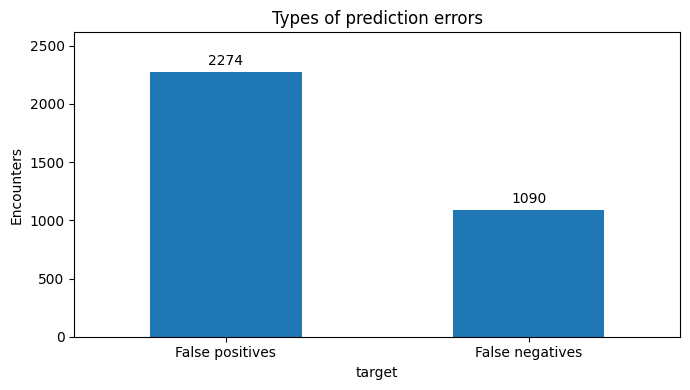

In [333]:
import pandas as pd
import matplotlib.pyplot as plt

audit = Xv.copy()

audit["result"] = "TN"
audit.loc[audit["target"].eq(0) & audit["y_pred"].eq(1), "result"] = "FP"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(0), "result"] = "FN"
audit.loc[audit["target"].eq(1) & audit["y_pred"].eq(1), "result"] = "TP"

error_counts = (Errors["target"].map({0: "False positives", 1: "False negatives"}).value_counts().reindex(["False positives", "False negatives"], fill_value=0))

ax = error_counts.plot.bar(figsize=(7, 4), rot=0)
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_ylabel("Encounters")
ax.set_title("Types of prediction errors")
ax.margins(y=0.15)
plt.tight_layout()
plt.show()

number_inpatient        number_emergency        time_in_hospital  \
                   mean median             mean median             mean   
result                                                                    
FP                 1.90    2.0             0.43    0.0             5.23   
TP                 2.29    2.0             0.60    0.0             5.20   

              num_medications         
       median            mean median  
result                                
FP        5.0           17.87   17.0  
TP        4.0           18.64   17.0

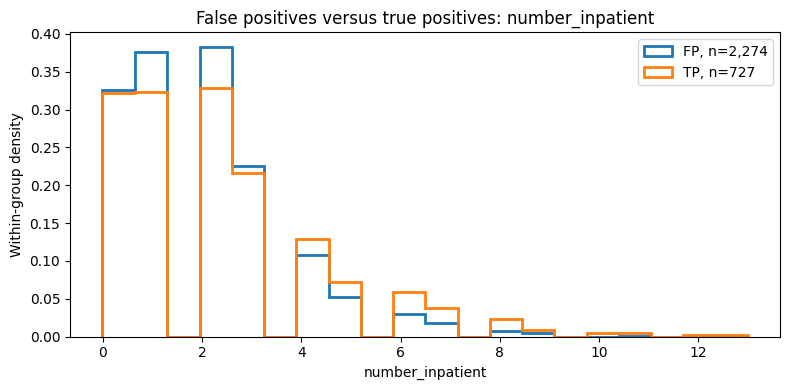

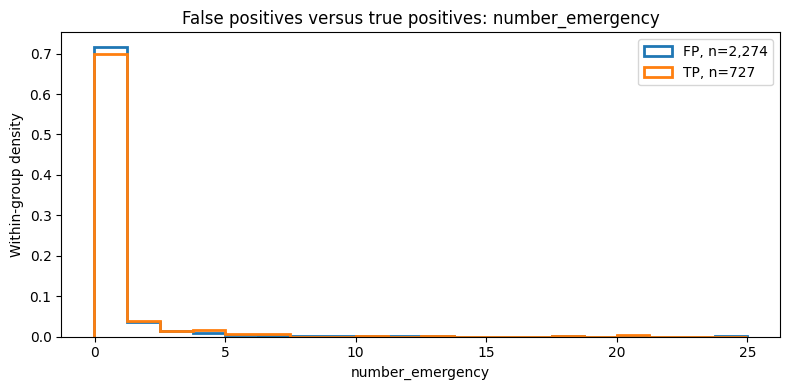

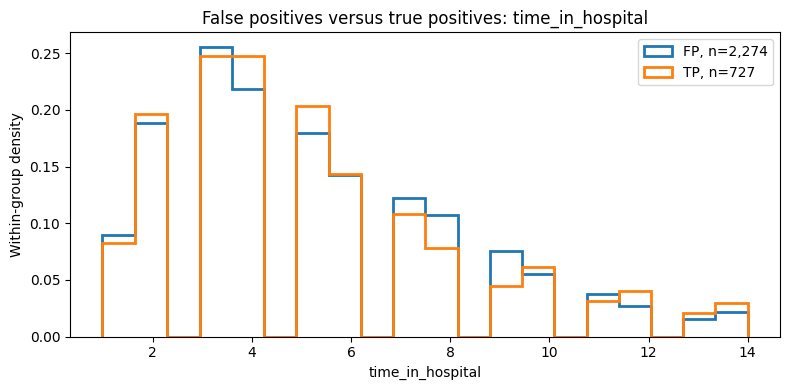

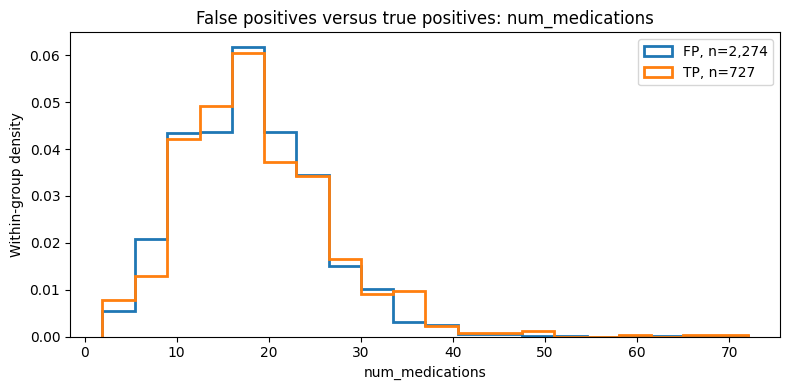

In [334]:
flagged = audit.loc[audit["y_pred"].eq(1)].copy()

columns = ["number_inpatient", "number_emergency", "time_in_hospital", "num_medications",]

display(flagged.groupby("result")[columns].agg(["mean", "median"]).round(2))

for column in columns:
    values = pd.to_numeric(flagged[column], errors="coerce")

    # use identical bin edges for both groups.
    edges = pd.cut(values.dropna(), bins=20, retbins=True)[1]

    plt.figure(figsize=(8, 4))

    for result in ["FP", "TP"]:
        group = values.loc[flagged["result"].eq(result)].dropna()
        plt.hist(group, bins=edges, density=True, histtype="step", linewidth=2, label=f"{result}, n={len(group):,}")

    plt.xlabel(column)
    plt.ylabel("Within-group density")
    plt.title(f"False positives versus true positives: {column}")
    plt.legend()
    plt.tight_layout()
    plt.show()

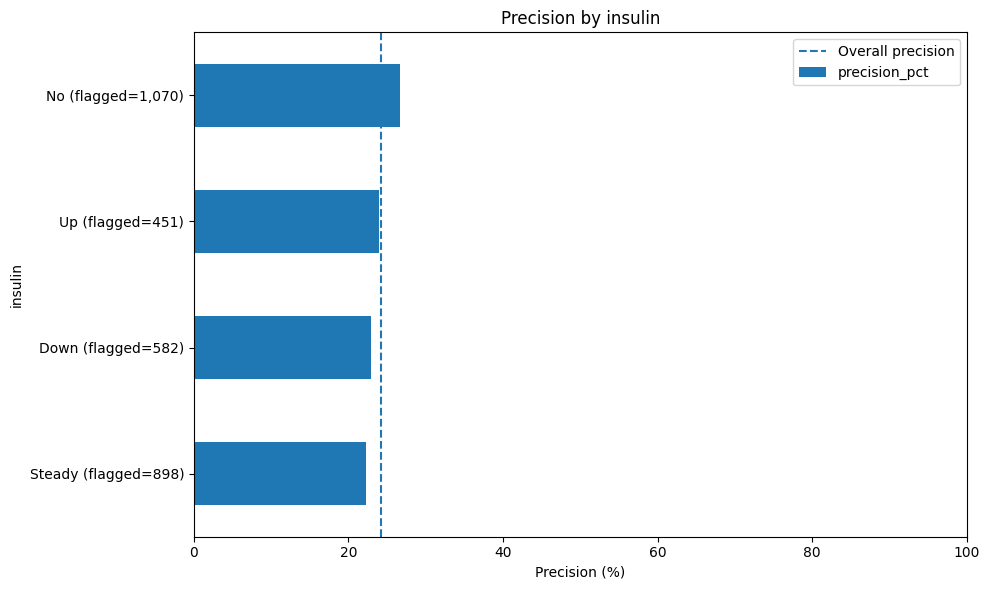

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
insulin,,,,,,,,
No,5936,784,492,286,1070,26.73,11.67,63.24
Steady,3718,698,326,200,898,22.27,15.81,61.98
Down,1296,449,150,133,582,22.85,25.73,53.00
Up,1242,343,122,108,451,23.95,21.64,53.04


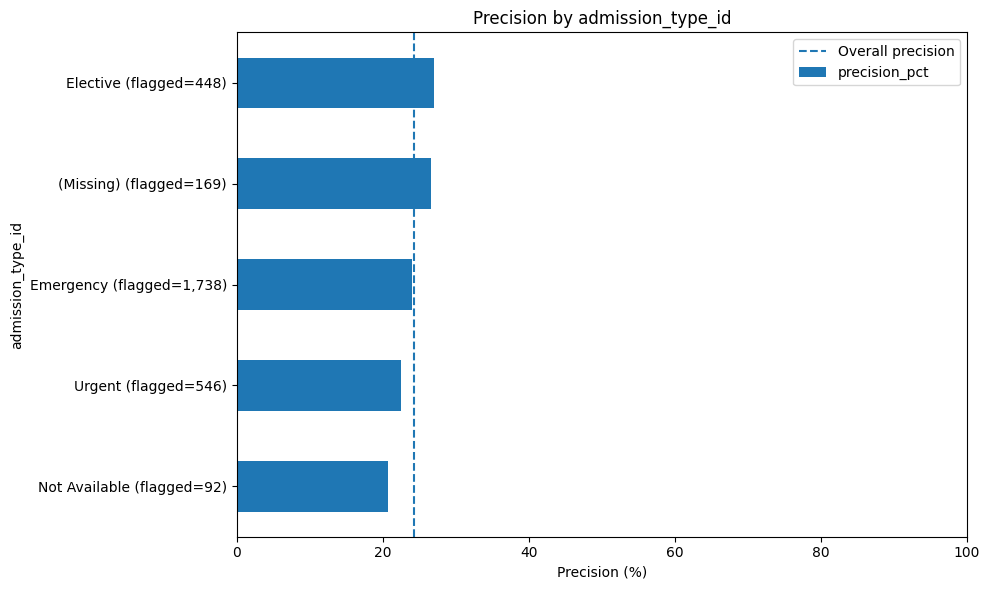

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
admission_type_id,,,,,,,,
Emergency,6308,1320,594,418,1738,24.05,17.30,58.70
Urgent,2178,423,194,123,546,22.53,16.26,61.20
Elective,2444,327,191,121,448,27.01,11.80,61.22
(Missing),613,124,46,45,169,26.63,16.82,50.55
Not Available,590,73,61,19,92,20.65,11.01,76.25
Not Mapped,51,7,4,1,8,12.50,12.07,80.00
Newborn,3,0,0,0,0,NaN,0.00,NaN
Trauma Center,5,0,0,0,0,NaN,0.00,NaN


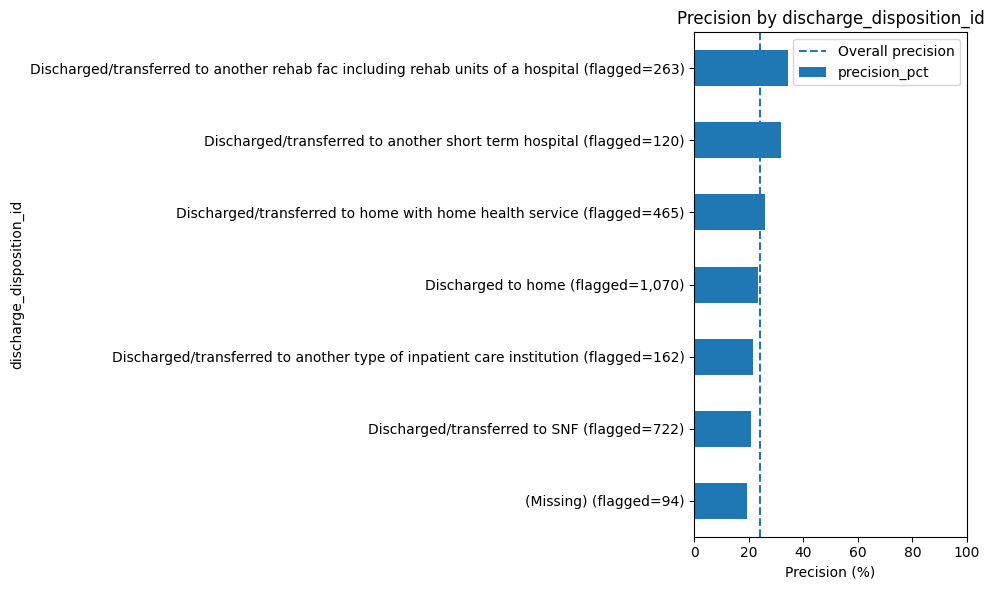

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
discharge_disposition_id,,,,,,,,
Discharged to home,7899,822,655,248,1070,23.18,9.43,72.54
Discharged/transferred to SNF,1324,571,171,151,722,20.91,30.13,53.11
Discharged/transferred to home with home health service,1389,344,126,121,465,26.02,19.85,51.01
Discharged/transferred to another rehab fac including rehab units of a hospital,59,173,11,90,263,34.22,74.57,10.89
Discharged/transferred to another type of inpatient care institution,58,127,9,35,162,21.60,68.65,20.45
Discharged/transferred to another short term hospital,225,82,16,38,120,31.67,26.71,29.63
(Missing),447,76,53,18,94,19.15,14.53,74.65
Discharged/transferred to ICF,100,19,12,6,25,24.00,15.97,66.67
Not Mapped,123,15,9,1,16,6.25,10.87,90.00


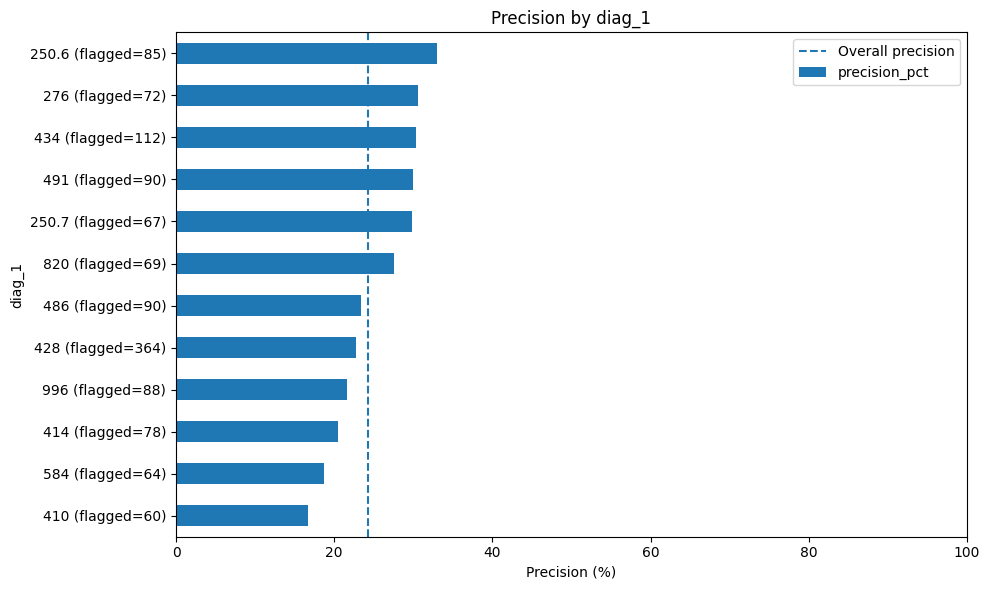

result,TN,FP,FN,TP,flagged,precision_pct,FPR_pct,FNR_pct
diag_1,,,,,,,,
428,653,281,73,83,364,22.80,30.09,46.79
434,193,78,24,34,112,30.36,28.78,41.38
486,458,69,24,21,90,23.33,13.09,53.33
996,189,69,24,19,88,21.59,26.74,55.81
491,262,63,32,27,90,30.00,19.38,54.24
414,899,62,80,16,78,20.51,6.45,83.33
250.6,98,57,20,28,85,32.94,36.77,41.67
584,181,52,16,12,64,18.75,22.32,57.14
820,87,50,9,19,69,27.54,36.50,32.14


In [335]:
# We perform error analysis on based on grouping of insulin, admission types, discharge dispositions, and the actual diagnoses

group_tables = {}
overall_precision = 100 * flagged["target"].mean()

for column in ["insulin", "admission_type_id", "discharge_disposition_id","diag_1"]:
    groups = audit[column].astype("string").fillna("(Missing)")

    table = pd.crosstab(groups, audit["result"]).reindex(columns=["TN", "FP", "FN", "TP"], fill_value=0)

    table["flagged"] = table["TP"] + table["FP"]
    negatives = table["TN"] + table["FP"]
    positives = table["TP"] + table["FN"]

    table["precision_pct"] = 100 * table["TP"] / table["flagged"].where(table["flagged"] > 0)
    

    table["FPR_pct"] = 100 * table["FP"] / negatives.where(negatives > 0)

    table["FNR_pct"] = 100 * table["FN"] / positives.where(positives > 0)

    group_tables[column] = table

    # Show common groups with at least 50 positive predictions.
    shown = table.loc[table["flagged"] >= 50].nlargest(12, "flagged").sort_values("precision_pct")

    ax = shown["precision_pct"].plot.barh(figsize=(10, 6))

    ax.set_yticks(range(len(shown)),[f"{group} (flagged={int(n):,})" for group, n in shown["flagged"].items()])

    ax.axvline(overall_precision, linestyle="--", label="Overall precision")

    ax.set_xlim(0, 100)
    ax.set_xlabel("Precision (%)")
    ax.set_title(f"Precision by {column}")
    ax.legend()
    plt.tight_layout()
    plt.show()

    # Rank by the actual number of false positives.
    display(table.sort_values("FP", ascending=False).head(12).round(2))

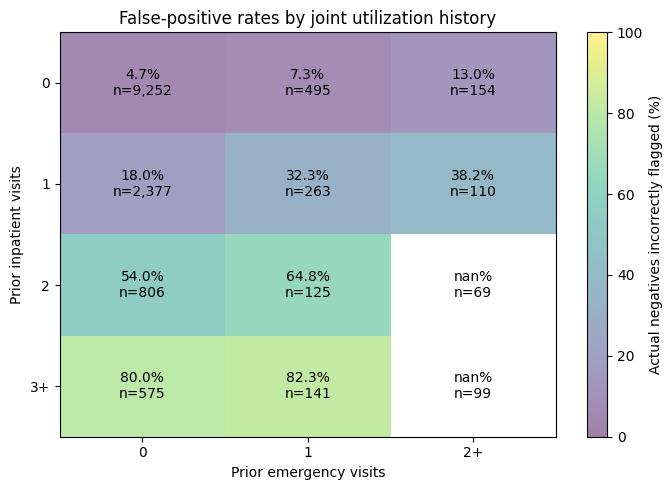

actual_negatives  false_positives    FPR
inpatient_band emergency_band                                          
0              0                           9252              436  0.047
               1                            495               36  0.073
               2+                           154               20  0.130
1              0                           2377              429  0.180
               1                            263               85  0.323
               2+                           110               42  0.382
2              0                            806              435  0.540
               1                            125               81  0.648
               2+                            69               50  0.725
3+             0                            575              460  0.800
               1                            141              116  0.823
               2+                            99               84  0.848

In [336]:
audit["inpatient_band"] = pd.cut(pd.to_numeric(audit["number_inpatient"], errors="coerce"), bins=[-float("inf"), 0, 1, 2, float("inf")], labels=["0", "1", "2", "3+"])

audit["emergency_band"] = pd.cut(pd.to_numeric(audit["number_emergency"], errors="coerce"), bins=[-float("inf"), 0, 1, float("inf")], labels=["0", "1", "2+"])

negative = audit.loc[audit["target"].eq(0)]

joint = negative.groupby(["inpatient_band", "emergency_band"], observed=True)["y_pred"].agg(actual_negatives="size", false_positives="sum", FPR="mean")

counts = joint["actual_negatives"].unstack().reindex(index=["0", "1", "2", "3+"],columns=["0", "1", "2+"]).fillna(0)

rates = 100 * joint["FPR"].unstack().reindex_like(counts)
shown = rates.where(counts >= 100)

plt.figure(figsize=(7, 5))
plt.imshow(shown.to_numpy(dtype=float), aspect="auto",vmin=0, vmax=100, alpha=0.5)

plt.xticks(range(len(shown.columns)), shown.columns)
plt.yticks(range(len(shown.index)), shown.index)

for i in range(len(shown.index)):
    for j in range(len(shown.columns)):
        plt.text(j, i, f"{shown.iloc[i, j]:.1f}%\nn={int(counts.iloc[i, j]):,}", ha="center", va="center")

plt.xlabel("Prior emergency visits")
plt.ylabel("Prior inpatient visits")
plt.title("False-positive rates by joint utilization history")
plt.colorbar(label="Actual negatives incorrectly flagged (%)")
plt.tight_layout()
plt.show()

display(joint.round(3))

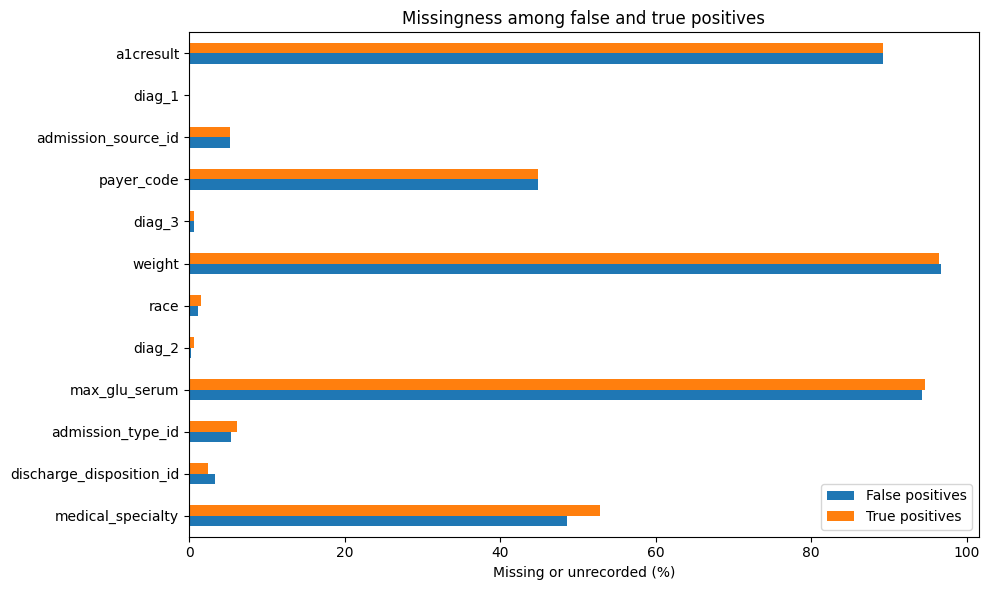

,False positives,True positives,difference_percentage_points
medical_specialty,48.55,52.82,-4.27
discharge_disposition_id,3.34,2.48,0.87
admission_type_id,5.45,6.19,-0.74
max_glu_serum,94.24,94.64,-0.40
diag_2,0.31,0.69,-0.38
race,1.19,1.51,-0.33
weight,96.75,96.42,0.32
diag_3,0.57,0.69,-0.12
payer_code,44.90,44.84,0.06
admission_source_id,5.28,5.23,0.05


In [337]:
columns = [column for column in flagged.columns if column not in ["target", "y_pred", "result", "patient_nbr", "encounter_id"]]

missing = flagged[columns].isna() | flagged[columns].astype("string").isin(["?", "", "missing"])

missing_rates = 100 * pd.DataFrame({"False positives": missing.loc[flagged["result"].eq("FP")].mean(),
                                    "True positives": missing.loc[flagged["result"].eq("TP")].mean()})

missing_rates = missing_rates.loc[missing_rates.gt(0).any(axis=1)]

difference = missing_rates["False positives"] - missing_rates["True positives"]

order = difference.abs().nlargest(12).index

if len(order):
    missing_rates.loc[order].plot.barh(figsize=(10, 6))
    plt.xlabel("Missing or unrecorded (%)")
    plt.ylabel("")
    plt.title("Missingness among false and true positives")
    plt.tight_layout()
    plt.show()

    display(missing_rates.assign(difference_percentage_points=difference).loc[order].round(2))